<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_16_Softmax_Probability_Distributions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

from transformers import AutoModelForCausalLM, GPT2Tokenizer

# Part 1: Softmax in NumPy and PyTorch


## Task_1:
- Transform the following list of numbers into a softmax distribution
by translating Equation 4.8 into NumPy code. Print the softmax
probabilities and confirm that they sum to 1.
z = [1,1.1,2,3,5,6,6.1]
Repeat the calculation using PyTorch’s softmax function. Be
mindful of datatypes. Print out the softmax probabilities and
confirm that they match the NumPy output.
Show both results in a graph as in Figure 4.2.

In [5]:
z = [1,1.1,2,3,5,6,6.1]
def softmax(z):
    z = np.asarray(z, dtype=np.float64)
    z = z - np.max(z)
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z)
softmax(z)

array([0.00263681, 0.00291413, 0.0071676 , 0.01948356, 0.1439651 ,
       0.39133772, 0.43249507])

In [3]:
zTorch = torch.tensor(z,dtype=torch.float32)

# using a function
zTorch_sm = F.softmax(zTorch,dim=-1)
zTorch_sm

tensor([0.0026, 0.0029, 0.0072, 0.0195, 0.1440, 0.3913, 0.4325])

In [6]:
num = np.exp(z)
den = np.sum( np.exp(z) )
sm = num / den

print(sm)
print(np.sum(sm))

[0.00263681 0.00291413 0.0071676  0.01948356 0.1439651  0.39133772
 0.43249507]
1.0


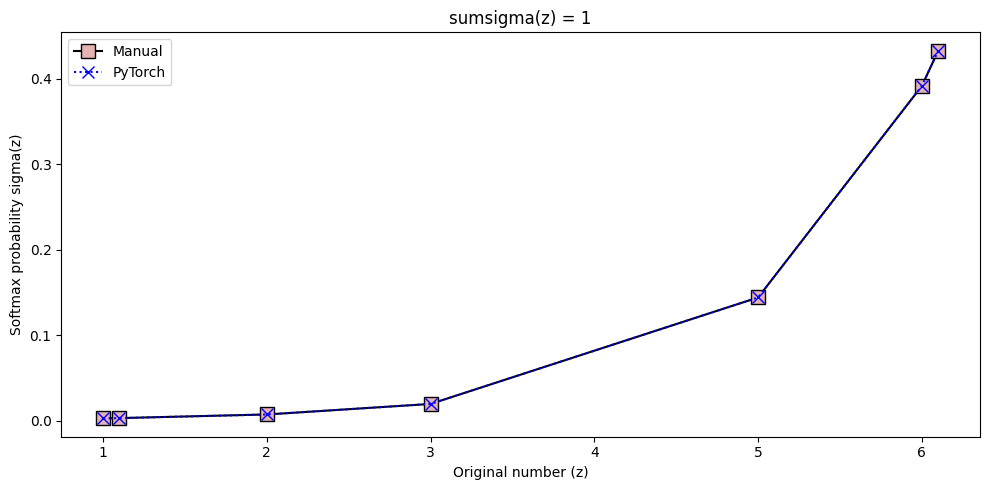

In [7]:

# compare
plt.figure(figsize=(10,5))

plt.plot(z,sm,'ks-',markerfacecolor=[.9,.7,.7],markersize=10,label='Manual')
plt.plot(z,zTorch_sm,'bx:',markersize=8,label='PyTorch')
plt.legend()

plt.gca().set(xlabel='Original number (z)',ylabel='Softmax probability sigma(z)',
              title='sumsigma(z) = %g' %np.sum(sm))

plt.tight_layout()
plt.savefig('ch4_proj16_part1.png')
plt.show()